In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("water_potability.csv")

# Check dataset shape and view first 5 rows
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [5]:
# Check missing values per feature
print("--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Target Distribution (0 = Non-Potable, 1 = Potable) ---")
print(df['Potability'].value_counts())

--- Missing Values Count ---
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

--- Target Distribution (0 = Non-Potable, 1 = Potable) ---
Potability
0    1998
1    1278
Name: count, dtype: int64


In [6]:
# Impute missing values using the median of each respective column
df['ph'] = df['ph'].fillna(df['ph'].median())
df['Sulfate'] = df['Sulfate'].fillna(df['Sulfate'].median())
df['Trihalomethanes'] = df['Trihalomethanes'].fillna(df['Trihalomethanes'].median())

# Confirm no missing values remain
print("Remaining missing values count:", df.isnull().sum().sum())

Remaining missing values count: 0


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import joblib

# Separate features and target
X = df.drop(columns=['Potability'])
y = df['Potability']

# 80-20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize feature values
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize the 3 models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

comparison_list = []

# Fit and evaluate each model
for model_name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    predictions = clf.predict(X_test_scaled)
    probabilities = clf.predict_proba(X_test_scaled)[:, 1]
    
    comparison_list.append({
        "Model": model_name,
        "Accuracy (%)": round(accuracy_score(y_test, predictions) * 100, 2),
        "Precision (%)": round(precision_score(y_test, predictions, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_test, predictions) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, predictions) * 100, 2),
        "ROC-AUC (%)": round(roc_auc_score(y_test, probabilities) * 100, 2)
    })

# Format and display summary comparison table
results_df = pd.DataFrame(comparison_list)
print("=== Model Comparison Metrics ===")
print(results_df.to_string(index=False))

# Save the best model and scaler for deployment
joblib.dump(models["Random Forest"], "water_quality_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("\nSaved 'water_quality_model.pkl' and 'scaler.pkl' successfully.")

=== Model Comparison Metrics ===
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  ROC-AUC (%)
Logistic Regression         60.98           0.00        0.00          0.00        54.81
      Random Forest         65.85          63.11       30.08         40.74        64.07
  Gradient Boosting         65.24          64.29       24.61         35.59        62.88

Saved 'water_quality_model.pkl' and 'scaler.pkl' successfully.


C:\Users\Asif\AppData\Local\Temp\ipykernel_24764\1980707329.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=[feature_names[i] for i in indices], palette="viridis")


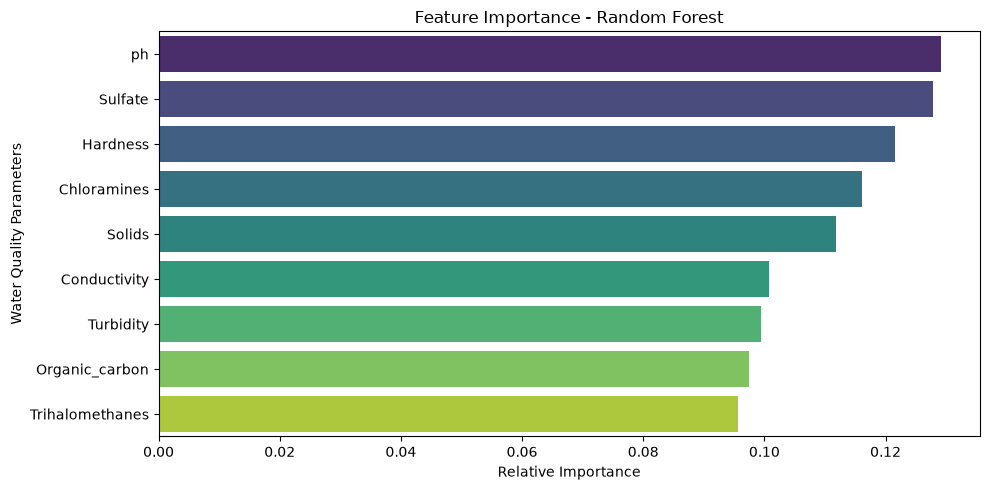

In [8]:
# Feature importance plot
feature_names = X.columns
importances = models["Random Forest"].feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.title("Feature Importance - Random Forest")
sns.barplot(x=importances[indices], y=[feature_names[i] for i in indices], palette="viridis")
plt.xlabel("Relative Importance")
plt.ylabel("Water Quality Parameters")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

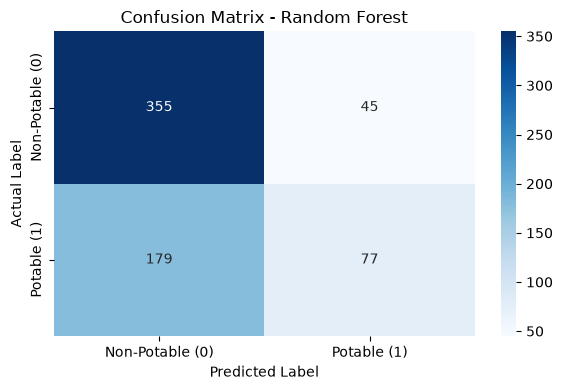

5-Fold Cross-Validation Accuracy Scores: [66.41 66.22 66.98 69.66 64.12]
Mean CV Accuracy: 66.68% (+/- 1.78%)



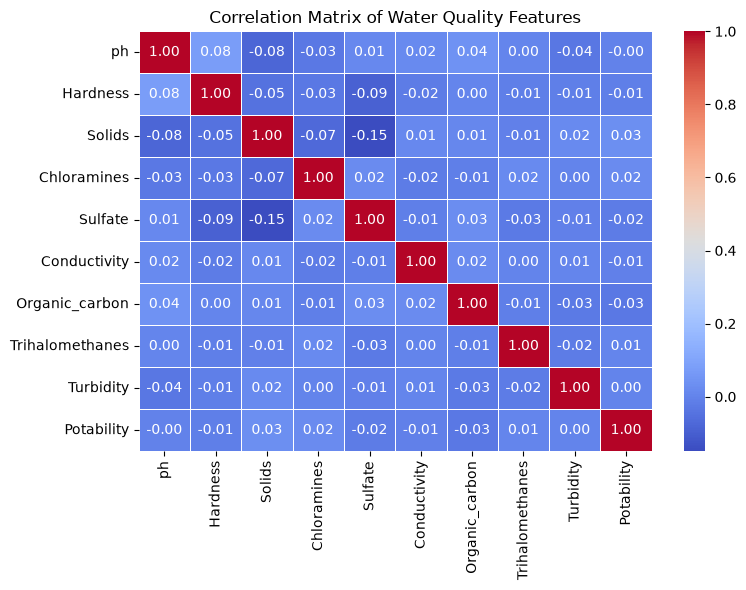

In [9]:
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score

# 1. Confusion Matrix Heatmap for Random Forest
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, models["Random Forest"].predict(X_test_scaled))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Non-Potable (0)', 'Potable (1)'], 
            yticklabels=['Non-Potable (0)', 'Potable (1)'])
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# 2. 5-Fold Cross-Validation Scores
cv_scores = cross_val_score(models["Random Forest"], X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"5-Fold Cross-Validation Accuracy Scores: {np.round(cv_scores * 100, 2)}")
print(f"Mean CV Accuracy: {round(cv_scores.mean() * 100, 2)}% (+/- {round(cv_scores.std() * 100, 2)}%)\n")

# 3. Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Correlation Matrix of Water Quality Features")
plt.tight_layout()
plt.savefig("correlation_matrix.png")
plt.show()